# 05 — Dataset Partitioning and Split Diagnostics

## Task 3: regression — synthetic crop-yield dataset

This notebook demonstrates common holdout strategies for a **continuous target**. It does not train a regression model and it does not build an end-to-end preprocessing pipeline.

Regression requires a different splitting discussion from classification because the target cannot normally be passed directly to `stratify=`.

## Learning objectives

After completing this notebook, students should be able to:

- distinguish TRAIN, VALIDATION, and TEST roles in regression;
- create random train/test and train/validation/test partitions;
- explain why a continuous target cannot be directly stratified;
- inspect target distributions across partitions;
- use temporary target quantile bins for optional approximate stratification;
- understand why quantile stratification is not automatically superior to random splitting;
- inspect numerical and categorical predictor differences;
- visualize split overlap using PCA fitted on TRAIN only;
- recognize when temporal, spatial, farm/group-aware, or other structured splits would be preferable.

## 1. Scope and an important ordering note

The notebook number reflects the **teaching sequence**. In a final machine-learning workflow the data partition is defined before fitting transformations such as scaling or supervised feature selection.

This notebook therefore loads the engineered feature table only so that the split diagnostics have a richer predictor space. It creates fresh partitions before fitting any diagnostic scaler or PCA.

## 2. Imports and reproducibility

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
PASTEL = sns.color_palette("pastel")

from scipy import stats
from scipy.stats import wasserstein_distance

## 3. Project paths and analytical roles

In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )


def three_way_random_split(df, train_fraction=0.70, validation_fraction=0.15, test_fraction=0.15):
    if not np.isclose(train_fraction + validation_fraction + test_fraction, 1.0):
        raise ValueError("Split fractions must sum to 1.0")

    holdout_fraction = validation_fraction + test_fraction
    train_df, holdout_df = train_test_split(
        df,
        test_size=holdout_fraction,
        random_state=RANDOM_STATE,
    )
    relative_test_fraction = test_fraction / holdout_fraction
    validation_df, test_df = train_test_split(
        holdout_df,
        test_size=relative_test_fraction,
        random_state=RANDOM_STATE,
    )
    return train_df.copy(), validation_df.copy(), test_df.copy()


def standardized_mean_difference(reference, comparison, columns):
    rows = []
    for feature in columns:
        train_mean = reference[feature].mean()
        train_sd = reference[feature].std(ddof=1)
        comparison_mean = comparison[feature].mean()
        smd = np.nan if np.isclose(train_sd, 0) else (comparison_mean - train_mean) / train_sd
        rows.append({
            "feature": feature,
            "train_mean": train_mean,
            "comparison_mean": comparison_mean,
            "smd": smd,
            "abs_smd": abs(smd) if pd.notna(smd) else np.nan,
        })
    return pd.DataFrame(rows)


def verify_three_way_split(full_df, train_df, validation_df, test_df, id_column):
    train_ids = set(train_df[id_column])
    validation_ids = set(validation_df[id_column])
    test_ids = set(test_df[id_column])

    assert train_ids.isdisjoint(validation_ids)
    assert train_ids.isdisjoint(test_ids)
    assert validation_ids.isdisjoint(test_ids)
    assert train_ids | validation_ids | test_ids == set(full_df[id_column])
    assert len(train_df) + len(validation_df) + len(test_df) == len(full_df)

    return pd.DataFrame({
        "split": ["train", "validation", "test"],
        "n": [len(train_df), len(validation_df), len(test_df)],
        "fraction": [len(train_df) / len(full_df), len(validation_df) / len(full_df), len(test_df) / len(full_df)],
    })



def pca_split_projection(train_df, validation_df, test_df, numerical_columns, id_column, target_column):
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train_df[numerical_columns])
    validation_scaled = scaler.transform(validation_df[numerical_columns])
    test_scaled = scaler.transform(test_df[numerical_columns])

    pca = PCA(n_components=min(5, len(numerical_columns)), random_state=RANDOM_STATE)
    train_scores = pca.fit_transform(train_scaled)
    validation_scores = pca.transform(validation_scaled)
    test_scores = pca.transform(test_scaled)

    def make_frame(scores, source, split_name):
        frame = pd.DataFrame(scores, columns=[f"PC{i+1}" for i in range(scores.shape[1])])
        frame[id_column] = source[id_column].to_numpy()
        frame[target_column] = source[target_column].to_numpy()
        frame["split"] = split_name
        return frame

    scores = pd.concat([
        make_frame(train_scores, train_df, "train"),
        make_frame(validation_scores, validation_df, "validation"),
        make_frame(test_scores, test_df, "test"),
    ], ignore_index=True)

    explained = pd.DataFrame({
        "component": [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
        "explained_variance_ratio": pca.explained_variance_ratio_,
    })

    centroid_rows = []
    train_centroid = scores.loc[scores["split"] == "train", [c for c in scores.columns if c.startswith("PC")]].mean().to_numpy()
    for split_name in ["train", "validation", "test"]:
        centroid = scores.loc[scores["split"] == split_name, [c for c in scores.columns if c.startswith("PC")]].mean().to_numpy()
        centroid_rows.append({
            "split": split_name,
            "distance_to_train_centroid": float(np.linalg.norm(centroid - train_centroid)),
        })

    return scores, explained, pd.DataFrame(centroid_rows)


PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / "data" / "synthetic_crop_yield"
FEATURE_DATA_PATH = DATASET_DIR / "feature_data" / "synthetic_crop_yield_engineered.csv"
PREPROCESSING_REPORT_PATH = DATASET_DIR / "processed_data" / "preprocessing_report.json"
FEATURE_MANIFEST_PATH = PROJECT_ROOT / "results" / "synthetic_crop_yield" / "feature_engineering_selection" / "feature_selection_manifest.json"
RESULTS_DIR = PROJECT_ROOT / "results" / "synthetic_crop_yield" / "dataset_splitting"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

for directory in [FIGURES_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

if not FEATURE_DATA_PATH.exists():
    raise FileNotFoundError("Engineered feature data are missing. Run notebook 03 first.")
if not PREPROCESSING_REPORT_PATH.exists() or not FEATURE_MANIFEST_PATH.exists():
    raise FileNotFoundError("Required metadata are missing. Run preprocessing and feature-selection notebooks first.")

with open(PREPROCESSING_REPORT_PATH, encoding="utf-8") as handle:
    preprocessing_report = json.load(handle)
with open(FEATURE_MANIFEST_PATH, encoding="utf-8") as handle:
    feature_manifest = json.load(handle)

df = pd.read_csv(FEATURE_DATA_PATH)
ID_COLUMN = preprocessing_report["identifier_column"]
TARGET_COLUMN = preprocessing_report["target_column"]
NUMERICAL_COLUMNS = feature_manifest["original_numerical_features"] + feature_manifest["engineered_numerical_features"]
CATEGORICAL_COLUMNS = feature_manifest["categorical_features"]

print("Dataset shape:", df.shape)
print("Identifier:", ID_COLUMN)
print("Continuous target:", TARGET_COLUMN)
print("Numerical predictors:", len(NUMERICAL_COLUMNS))
print("Categorical predictors:", len(CATEGORICAL_COLUMNS))
display(df.head())

Dataset shape: (1200, 30)
Identifier: plot_id
Continuous target: yield_t_ha
Numerical predictors: 22
Categorical predictors: 6


,plot_id,mean_temperature_c,season_rainfall_mm,soil_ph,soil_organic_matter_pct,nitrogen_kg_ha,phosphorus_kg_ha,potassium_kg_ha,irrigation_mm,solar_radiation_mj_m2_day,...,yield_t_ha,total_water_mm,npk_total_kg_ha,n_to_p_ratio,mean_temperature_c_squared,soil_ph_squared,soil_moisture_pct_squared,water_x_drought,pest_x_fungicide,organic_matter_x_moisture
0,CP0001,20.7,273.7,7.21,3.80,136.6,57.4,38.5,88.3,15.4,...,5.38,362.0,232.5,2.379791,428.49,51.9841,795.24,0.0,2.7,107.160
1,CP0002,24.6,237.9,7.10,2.76,155.4,56.3,113.9,270.5,15.4,...,3.93,508.4,325.6,2.760213,605.16,50.4100,767.29,508.4,6.3,76.452
2,CP0003,20.4,192.5,7.16,2.95,121.6,51.9,49.6,62.2,14.6,...,3.10,254.7,223.1,2.342967,416.16,51.2656,449.44,254.7,0.0,62.540
3,CP0004,24.6,599.3,6.60,4.79,182.7,81.5,97.3,137.4,19.7,...,6.61,736.7,361.5,2.241718,605.16,43.5600,1108.89,0.0,0.0,159.507
4,CP0005,11.0,603.6,6.62,2.97,122.8,47.8,97.2,76.1,15.8,...,0.70,679.7,267.8,2.569038,121.00,43.8244,1225.00,0.0,7.2,103.950


## 4. Train/test versus train/validation/test for regression

The same logic used in classification applies here. If model selection will be performed using cross-validation inside TRAIN, an explicit permanent validation set may be unnecessary.

A dedicated validation set is useful for procedures such as early stopping or repeated development decisions.

Because our current goal is demonstration rather than model fitting, we will show both a simple `80/20` holdout and a `70/15/15` partition.

# Part I — Random regression holdout

## 5. Create a random 80/20 split

For ordinary independent regression observations, random holdout is a common starting point.

In [3]:
random_train, random_test = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print("TRAIN:", random_train.shape)
print("TEST:", random_test.shape)

TRAIN: (960, 30)
TEST: (240, 30)


## 6. Compare the continuous target across the 80/20 partitions

In [4]:
def target_summary(parts, target_column):
    rows = []
    for split_name, split_df in parts.items():
        y = split_df[target_column]
        rows.append({
            "split": split_name,
            "n": len(split_df),
            "mean": y.mean(),
            "std": y.std(ddof=1),
            "min": y.min(),
            "q10": y.quantile(0.10),
            "q25": y.quantile(0.25),
            "median": y.median(),
            "q75": y.quantile(0.75),
            "q90": y.quantile(0.90),
            "max": y.max(),
        })
    return pd.DataFrame(rows)

random_target_summary = target_summary(
    {"full": df, "train": random_train, "test": random_test},
    TARGET_COLUMN,
)
display(random_target_summary.round(3))

,split,n,mean,std,min,q10,q25,median,q75,q90,max
0,full,1200,4.282,1.470,0.7,2.308,3.280,4.43,5.320,6.021,8.11
1,train,960,4.268,1.485,0.7,2.289,3.295,4.37,5.300,6.091,8.11
2,test,240,4.334,1.410,0.7,2.328,3.250,4.63,5.415,5.853,7.41


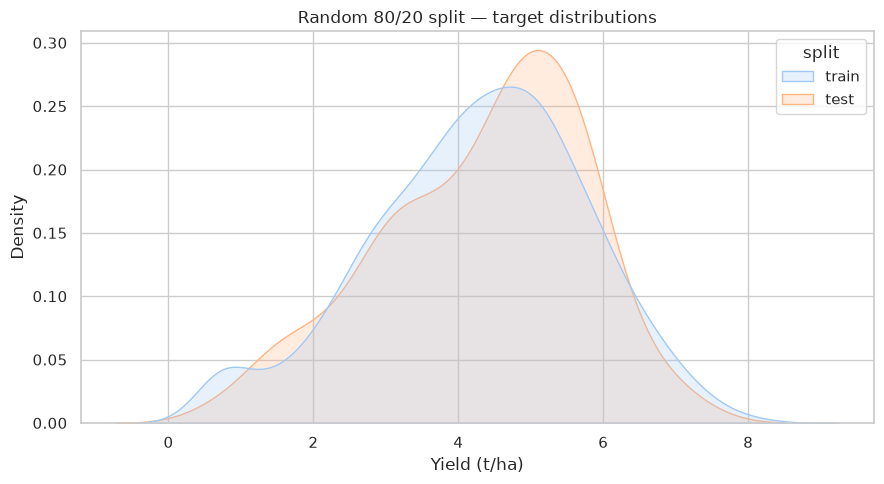

In [5]:
random_plot = pd.concat([
    random_train[[TARGET_COLUMN]].assign(split="train"),
    random_test[[TARGET_COLUMN]].assign(split="test"),
], ignore_index=True)

plt.figure(figsize=(9, 5))
sns.kdeplot(
    data=random_plot,
    x=TARGET_COLUMN,
    hue="split",
    common_norm=False,
    fill=True,
    alpha=0.25,
    palette="pastel",
)
plt.title("Random 80/20 split — target distributions")
plt.xlabel("Yield (t/ha)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_random_train_test_target_kde.png", dpi=160, bbox_inches="tight")
plt.show()

# Part II — Random TRAIN / VALIDATION / TEST

## 7. Create a reproducible 70/15/15 random split

In [6]:
train_df, validation_df, test_df = three_way_random_split(
    df,
    train_fraction=0.70,
    validation_fraction=0.15,
    test_fraction=0.15,
)

split_size_table = verify_three_way_split(
    df, train_df, validation_df, test_df, ID_COLUMN
)
display(split_size_table.assign(fraction_pct=lambda x: 100 * x["fraction"]).round(2))

,split,n,fraction,fraction_pct
0,train,840,0.70,70.0
1,validation,180,0.15,15.0
2,test,180,0.15,15.0


## 8. Inspect the target distribution across the three partitions

In [7]:
target_summary_table = target_summary(
    {"full": df, "train": train_df, "validation": validation_df, "test": test_df},
    TARGET_COLUMN,
)
display(target_summary_table.round(3))
target_summary_table.to_csv(TABLES_DIR / "target_summary_by_split.csv", index=False)
split_size_table.to_csv(TABLES_DIR / "split_sizes.csv", index=False)

,split,n,mean,std,min,q10,q25,median,q75,q90,max
0,full,1200,4.282,1.470,0.7,2.308,3.280,4.430,5.320,6.021,8.11
1,train,840,4.232,1.499,0.7,2.210,3.258,4.340,5.272,6.081,7.90
2,validation,180,4.357,1.436,0.7,2.355,3.378,4.550,5.435,5.990,8.11
3,test,180,4.437,1.358,0.7,2.619,3.485,4.755,5.453,5.904,7.23


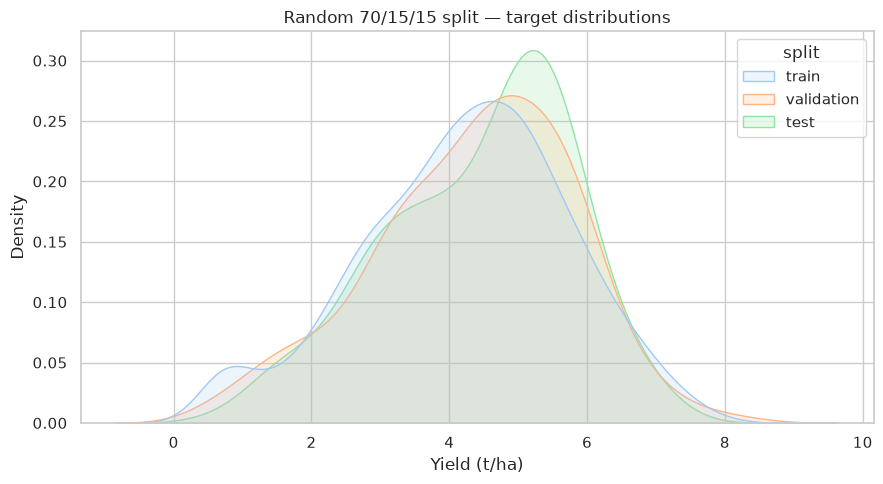

In [8]:
target_long = pd.concat([
    train_df[[TARGET_COLUMN]].assign(split="train"),
    validation_df[[TARGET_COLUMN]].assign(split="validation"),
    test_df[[TARGET_COLUMN]].assign(split="test"),
], ignore_index=True)

plt.figure(figsize=(9, 5))
sns.kdeplot(
    data=target_long,
    x=TARGET_COLUMN,
    hue="split",
    common_norm=False,
    fill=True,
    alpha=0.20,
    palette="pastel",
)
plt.title("Random 70/15/15 split — target distributions")
plt.xlabel("Yield (t/ha)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_random_three_way_target_kde.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Quantify target-distribution differences descriptively

We compare each held-out distribution with TRAIN using:

- a difference in mean expressed in TRAIN standard-deviation units;
- Wasserstein distance in the original target units;
- the two-sample Kolmogorov-Smirnov statistic.

These are diagnostics, not automatic pass/fail criteria.

In [9]:
target_diagnostics = []
train_y = train_df[TARGET_COLUMN].to_numpy()
train_sd = train_df[TARGET_COLUMN].std(ddof=1)

for split_name, split_df in [("validation", validation_df), ("test", test_df)]:
    split_y = split_df[TARGET_COLUMN].to_numpy()
    ks = stats.ks_2samp(train_y, split_y)
    target_diagnostics.append({
        "split": split_name,
        "target_mean_smd": (split_df[TARGET_COLUMN].mean() - train_df[TARGET_COLUMN].mean()) / train_sd,
        "wasserstein_distance_t_ha": wasserstein_distance(train_y, split_y),
        "ks_statistic": ks.statistic,
        "ks_p_value": ks.pvalue,
    })

target_diagnostics = pd.DataFrame(target_diagnostics)
display(target_diagnostics.round(4))
target_diagnostics.to_csv(TABLES_DIR / "target_distribution_diagnostics.csv", index=False)

,split,target_mean_smd,wasserstein_distance_t_ha,ks_statistic,ks_p_value
0,validation,0.0836,0.1592,0.0671,0.4969
1,test,0.1364,0.2653,0.1194,0.0268


# Part III — Optional approximate stratification for regression

## 10. Temporary quantile bins

A continuous target cannot normally be passed directly to `stratify`. One optional strategy is to create temporary target-quantile bins **only for assigning rows to partitions**.

The original `yield_t_ha` remains continuous and would still be used as the regression target.

This is not automatically better than random splitting. Group, temporal, or spatial structure should take priority when those constraints exist.

In [10]:
regression_bins = pd.qcut(
    df[TARGET_COLUMN],
    q=10,
    labels=False,
    duplicates="drop",
)

quantile_df = df.assign(_target_quantile_bin=regression_bins)

q_train, q_holdout = train_test_split(
    quantile_df,
    test_size=0.30,
    stratify=quantile_df["_target_quantile_bin"],
    random_state=RANDOM_STATE,
)
q_validation, q_test = train_test_split(
    q_holdout,
    test_size=0.50,
    stratify=q_holdout["_target_quantile_bin"],
    random_state=RANDOM_STATE,
)

q_train = q_train.drop(columns="_target_quantile_bin")
q_validation = q_validation.drop(columns="_target_quantile_bin")
q_test = q_test.drop(columns="_target_quantile_bin")

verify_three_way_split(df, q_train, q_validation, q_test, ID_COLUMN)
quantile_target_summary = target_summary(
    {"train": q_train, "validation": q_validation, "test": q_test},
    TARGET_COLUMN,
)
display(quantile_target_summary.round(3))

,split,n,mean,std,min,q10,q25,median,q75,q90,max
0,train,840,4.278,1.448,0.7,2.308,3.278,4.430,5.320,6.021,7.60
1,validation,180,4.328,1.497,0.7,2.351,3.290,4.445,5.292,6.057,8.11
2,test,180,4.249,1.552,0.7,2.349,3.332,4.380,5.345,6.008,7.90


In [11]:
comparison_rows = []
for strategy_name, parts in {
    "random": {"train": train_df, "validation": validation_df, "test": test_df},
    "quantile_stratified": {"train": q_train, "validation": q_validation, "test": q_test},
}.items():
    train_mean = parts["train"][TARGET_COLUMN].mean()
    train_sd_local = parts["train"][TARGET_COLUMN].std(ddof=1)
    for split_name in ["validation", "test"]:
        split_y = parts[split_name][TARGET_COLUMN]
        comparison_rows.append({
            "strategy": strategy_name,
            "split": split_name,
            "absolute_target_mean_smd": abs((split_y.mean() - train_mean) / train_sd_local),
            "wasserstein_distance_t_ha": wasserstein_distance(parts["train"][TARGET_COLUMN], split_y),
        })

strategy_comparison = pd.DataFrame(comparison_rows)
display(strategy_comparison.round(4))
strategy_comparison.to_csv(TABLES_DIR / "random_vs_quantile_stratification.csv", index=False)

,strategy,split,absolute_target_mean_smd,wasserstein_distance_t_ha
0,random,validation,0.0836,0.1592
1,random,test,0.1364,0.2653
2,quantile_stratified,validation,0.0346,0.0810
3,quantile_stratified,test,0.0201,0.0916


### Interpretation

Quantile-bin stratification often makes the marginal target distributions look more similar by construction. That does **not** prove it is the more scientifically appropriate split.

If this dataset represented multiple years, farms, geographic regions, or repeated plots, those structures could be more important than matching target quantiles.

# Part IV — Inspect predictor-space differences for the random 70/15/15 split

## 11. Numerical predictors — standardized mean differences

In [12]:
validation_smd = standardized_mean_difference(train_df, validation_df, NUMERICAL_COLUMNS)
validation_smd["comparison_split"] = "validation"
test_smd = standardized_mean_difference(train_df, test_df, NUMERICAL_COLUMNS)
test_smd["comparison_split"] = "test"

smd_table = pd.concat([validation_smd, test_smd], ignore_index=True)
smd_table = smd_table.sort_values("abs_smd", ascending=False).reset_index(drop=True)
display(smd_table.head(20).round(3))
smd_table.to_csv(TABLES_DIR / "numerical_standardized_mean_differences.csv", index=False)

,feature,train_mean,comparison_mean,smd,abs_smd,comparison_split
0,pest_x_fungicide,1.699,2.089,0.178,0.178,validation
1,nitrogen_kg_ha,123.919,128.979,0.125,0.125,validation
2,field_slope_pct,3.842,3.503,-0.124,0.124,test
3,pest_pressure_score_0_10,3.507,3.292,-0.121,0.121,test
4,pest_x_fungicide,1.699,1.439,-0.119,0.119,test
5,npk_total_kg_ha,260.093,265.946,0.116,0.116,validation
6,irrigation_mm,150.621,158.346,0.091,0.091,validation
7,phosphorus_kg_ha,57.702,56.262,-0.075,0.075,test
8,phosphorus_kg_ha,57.702,59.091,0.072,0.072,validation
9,n_to_p_ratio,2.545,2.665,0.067,0.067,test


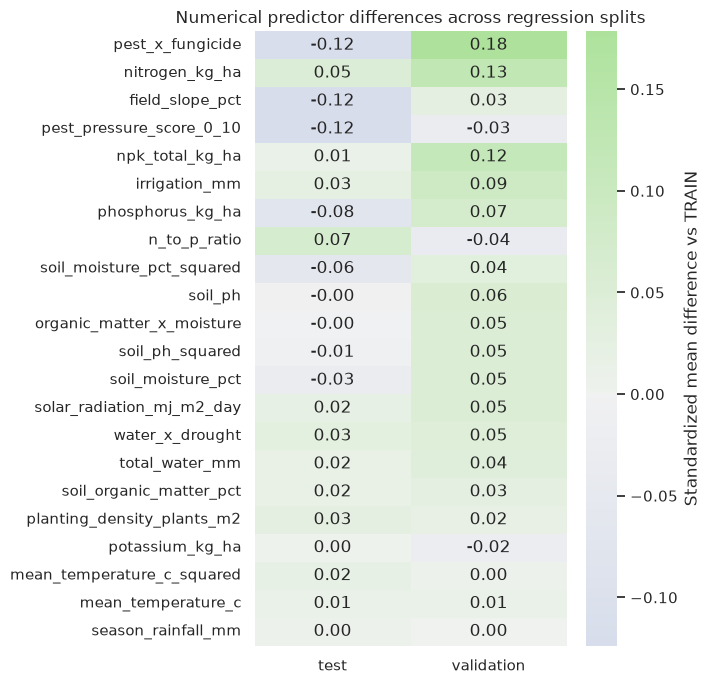

In [13]:
smd_heatmap = smd_table.pivot(index="feature", columns="comparison_split", values="smd")
smd_heatmap = smd_heatmap.loc[smd_heatmap.abs().max(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(7, max(7, 0.30 * len(smd_heatmap))))
sns.heatmap(
    smd_heatmap,
    cmap=sns.diverging_palette(250, 120, s=45, l=85, as_cmap=True),
    center=0,
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "Standardized mean difference vs TRAIN"},
)
plt.title("Numerical predictor differences across regression splits")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_numerical_smd_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Categorical predictors — prevalence differences

In [14]:
categorical_rows = []
for feature in CATEGORICAL_COLUMNS:
    train_prevalence = 100 * train_df[feature].mean()
    for split_name, split_df in [("validation", validation_df), ("test", test_df)]:
        prevalence = 100 * split_df[feature].mean()
        categorical_rows.append({
            "feature": feature,
            "split": split_name,
            "train_prevalence_pct": train_prevalence,
            "split_prevalence_pct": prevalence,
            "difference_percentage_points": prevalence - train_prevalence,
        })

categorical_drift = pd.DataFrame(categorical_rows).sort_values(
    "difference_percentage_points", key=lambda s: s.abs(), ascending=False
)
display(categorical_drift.round(2))
categorical_drift.to_csv(TABLES_DIR / "categorical_prevalence_differences.csv", index=False)

,feature,split,train_prevalence_pct,split_prevalence_pct,difference_percentage_points
8,fungicide_used,validation,46.07,53.33,7.26
7,organic_management,test,22.98,28.89,5.91
0,irrigation_system_drip,validation,37.26,42.78,5.52
9,fungicide_used,test,46.07,40.56,-5.52
5,previous_legume_crop,test,29.40,32.78,3.37
1,irrigation_system_drip,test,37.26,40.56,3.29
10,drought_event,validation,21.31,24.44,3.13
6,organic_management,validation,22.98,25.56,2.58
2,cultivar_improved,validation,57.14,59.44,2.30
11,drought_event,test,21.31,22.78,1.47


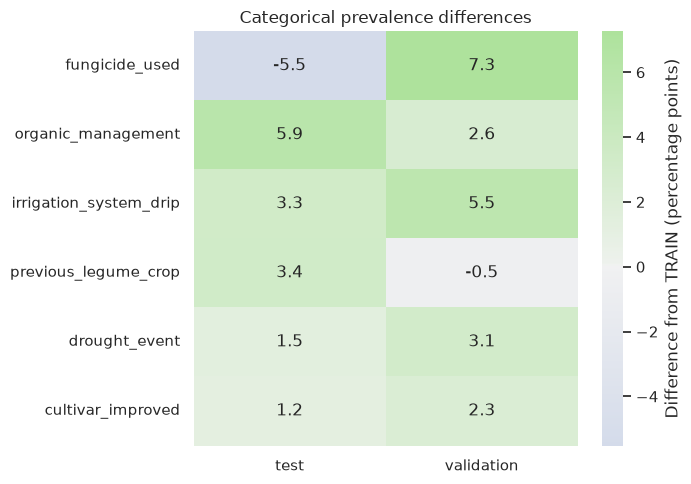

In [15]:
categorical_heatmap = categorical_drift.pivot(
    index="feature", columns="split", values="difference_percentage_points"
)
categorical_heatmap = categorical_heatmap.loc[
    categorical_heatmap.abs().max(axis=1).sort_values(ascending=False).index
]

plt.figure(figsize=(7, max(5, 0.50 * len(categorical_heatmap))))
sns.heatmap(
    categorical_heatmap,
    cmap=sns.diverging_palette(250, 120, s=45, l=85, as_cmap=True),
    center=0,
    annot=True,
    fmt=".1f",
    cbar_kws={"label": "Difference from TRAIN (percentage points)"},
)
plt.title("Categorical prevalence differences")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_categorical_prevalence_differences.png", dpi=160, bbox_inches="tight")
plt.show()

# Part V — Multivariate split-space diagnostics

## 13. PCA fitted on TRAIN only

We fit `StandardScaler` and PCA using only TRAIN numerical predictors, then transform VALIDATION and TEST. PCA is used here as an exploratory split diagnostic, not as a predictive model.

In [16]:
pca_scores, pca_explained, pca_centroid_shift = pca_split_projection(
    train_df, validation_df, test_df, NUMERICAL_COLUMNS, ID_COLUMN, TARGET_COLUMN
)

display(pca_explained.round(4))
display(pca_centroid_shift.round(4))
pca_scores.to_csv(TABLES_DIR / "pca_split_scores.csv", index=False)
pca_explained.to_csv(TABLES_DIR / "pca_explained_variance.csv", index=False)
pca_centroid_shift.to_csv(TABLES_DIR / "pca_centroid_shift.csv", index=False)

,component,explained_variance_ratio
0,PC1,0.1727
1,PC2,0.0957
2,PC3,0.0950
3,PC4,0.0908
4,PC5,0.0785


,split,distance_to_train_centroid
0,train,0.0000
1,validation,0.2114
2,test,0.1150


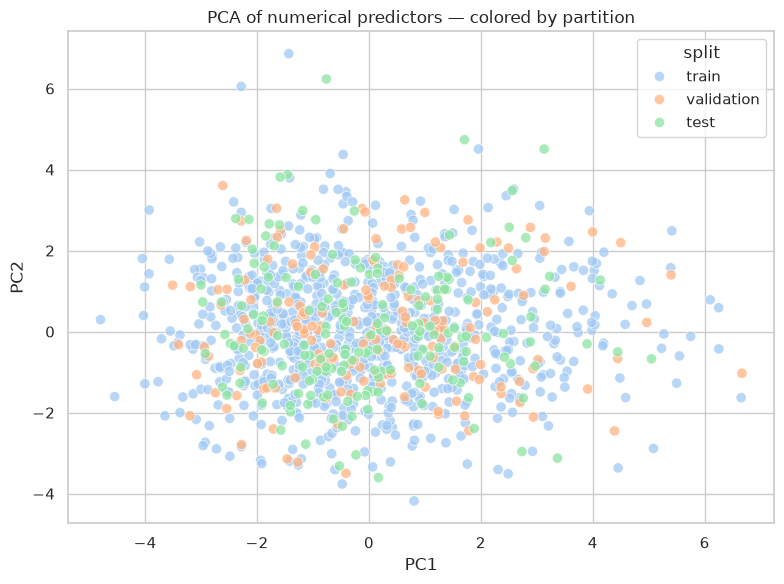

In [17]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_scores,
    x="PC1",
    y="PC2",
    hue="split",
    palette="pastel",
    alpha=0.75,
    s=55,
)
plt.title("PCA of numerical predictors — colored by partition")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_pca_by_split.png", dpi=160, bbox_inches="tight")
plt.show()

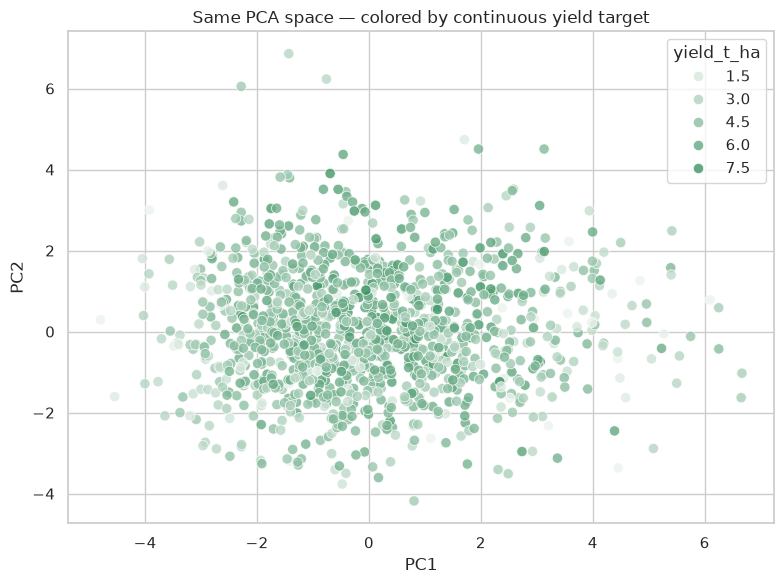

In [18]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_scores,
    x="PC1",
    y="PC2",
    hue=TARGET_COLUMN,
    palette=sns.light_palette("seagreen", as_cmap=True),
    alpha=0.80,
    s=55,
    legend="brief",
)
plt.title("Same PCA space — colored by continuous yield target")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_pca_by_target.png", dpi=160, bbox_inches="tight")
plt.show()

### How to read the PCA diagnostic

Because the synthetic rows are generated as independent observations from one population, broad overlap among TRAIN, VALIDATION, and TEST is expected.

In a real agricultural study, clear separation could reflect meaningful structure such as year, farm, region, cultivar deployment, climate regime, or measurement batch. In that case, a random split might be hiding the more scientifically relevant evaluation problem.

# Part VI — Save realized assignments

## 14. Export the random 70/15/15 demonstration split and the optional quantile-stratified split

In [19]:
random_assignments = pd.concat([
    train_df[[ID_COLUMN, TARGET_COLUMN]].assign(split="train"),
    validation_df[[ID_COLUMN, TARGET_COLUMN]].assign(split="validation"),
    test_df[[ID_COLUMN, TARGET_COLUMN]].assign(split="test"),
], ignore_index=True).sort_values(ID_COLUMN).reset_index(drop=True)

quantile_assignments = pd.concat([
    q_train[[ID_COLUMN, TARGET_COLUMN]].assign(split="train"),
    q_validation[[ID_COLUMN, TARGET_COLUMN]].assign(split="validation"),
    q_test[[ID_COLUMN, TARGET_COLUMN]].assign(split="test"),
], ignore_index=True).sort_values(ID_COLUMN).reset_index(drop=True)

random_assignments.to_csv(TABLES_DIR / "split_assignments_random_70_15_15.csv", index=False)
quantile_assignments.to_csv(TABLES_DIR / "split_assignments_quantile_stratified_70_15_15.csv", index=False)

split_manifest = {
    "primary_demonstration_strategy": "random train/validation/test holdout",
    "secondary_strategy": "target-quantile-bin stratified holdout",
    "random_state": RANDOM_STATE,
    "train_fraction": 0.70,
    "validation_fraction": 0.15,
    "test_fraction": 0.15,
    "target_quantile_bins": 10,
    "identifier_column": ID_COLUMN,
    "target_column": TARGET_COLUMN,
    "note": "Quantile bins are used only for optional split assignment; the original target remains continuous. These are demonstration splits, not a frozen benchmark definition.",
}
with open(RESULTS_DIR / "split_manifest.json", "w", encoding="utf-8") as handle:
    json.dump(split_manifest, handle, indent=2)

print("Exported split assignments and manifest to:", RESULTS_DIR.relative_to(PROJECT_ROOT))

Exported split assignments and manifest to: results/synthetic_crop_yield/dataset_splitting


# 15. What this notebook did — and did not do

We demonstrated:

```text
random train/test
random train/validation/test
continuous-target distribution checks
optional quantile-bin stratification
SMD predictor diagnostics
categorical prevalence diagnostics
PCA visualization of split space
reproducible split export
```

We deliberately did **not**:

- discretize the target for modelling;
- train a regression model;
- choose a “best” split using test performance;
- build a full preprocessing pipeline;
- implement spatial, temporal, farm-aware, or other structured splitting.

Those structured strategies can be more appropriate for real agricultural data and are discussed in the accompanying documentation.

## Final takeaway

For independent regression data, random splitting is a reasonable starting point. Because the target is continuous, the important diagnostic is not class balance but whether TRAIN, VALIDATION, and TEST reasonably cover the target and predictor spaces.

Temporary target bins can be used for approximate stratification, but they are a sampling device rather than a transformation of the regression problem. More importantly, natural groups, time, and space should determine the evaluation design whenever they reflect how the model will be deployed.